In [1]:
import csv
import matplotlib.pyplot as plt
import pandas as pd
import cantera as ct

In [2]:
d = ct.Interface("diamond.yaml", "diamond_100")
g = d.adjacent["gas"]
dbulk = d.adjacent["diamond"]

mw = dbulk.molecular_weights[0]

t = 1200.0
x = g.X
p = 20.0 * ct.one_atm / 760.0  # 20 Torr
g.TP = t, p

ih = g.species_index('H')

xh0 = x[ih]

In [3]:
with open('diamond.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['H mole Fraction', 'Growth Rate (microns/hour)'] +
                    d.species_names)

    iC = d.kinetics_species_index('C(d)')

    for n in range(20):
        x[ih] /= 1.4
        g.TPX = t, p, x
        d.advance_coverages(10.0)  # integrate the coverages to steady state
        carbon_dot = d.net_production_rates[iC]
        mdot = mw * carbon_dot
        rate = mdot / dbulk.density
        writer.writerow([x[ih], rate * 1.0e6 * 3600.0] + list(d.coverages))

    print('H concentration, growth rate, and surface coverages '
          'written to file diamond.csv')

H concentration, growth rate, and surface coverages written to file diamond.csv


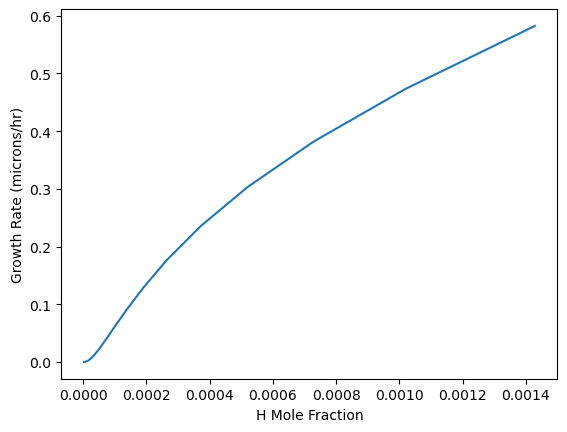

In [4]:
data = pd.read_csv('diamond.csv')

data.plot(x="H mole Fraction", y="Growth Rate (microns/hour)", legend=False)
plt.xlabel('H Mole Fraction')
plt.ylabel('Growth Rate (microns/hr)')
plt.show()

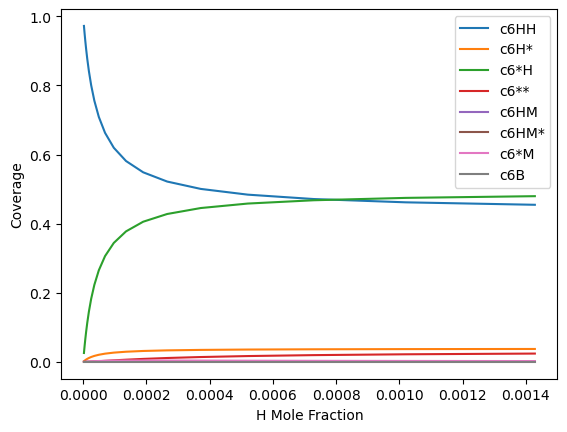

In [ ]:
names = [name for name in data.columns if not name.startswith(('H mole', 'Growth'))]
data.plot(x='H mole Fraction', y=names, legend=True)
plt.xlabel('H Mole Fraction')
plt.ylabel('Coverage')
plt.show()